In [1]:

# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")


ModuleNotFoundError: No module named 'seaborn'

In [ ]:
data = pd.read_csv("/kaggle/input/cafe-sales-dirty-data-for-cleaning-training/dirty_cafe_sales.csv")

In [ ]:
data.head(10)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


In [ ]:
data.shape

(10000, 8)

In [ ]:
data.columns

Index(['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent',
       'Payment Method', 'Location', 'Transaction Date'],
      dtype='object')

In [ ]:
data.isnull().sum()

Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64

# cleaning

## 1- Drop Transaction ID cuz i don't need it in analysis

In [ ]:
data.drop('Transaction ID', axis=1, inplace=True)

In [ ]:
data.head(5)

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


## 2- Show data types to convert each column to the suitable Type 

In [ ]:
data.dtypes

Item                object
Quantity            object
Price Per Unit      object
Total Spent         object
Payment Method      object
Location            object
Transaction Date    object
dtype: object

## 3- Convert : 
    - Quantity & Price Per Unit to numerical value. 
    - Transaction Date to datetime format


In [ ]:
data['Quantity'] = pd.to_numeric(data['Quantity'], errors='coerce')
data['Price Per Unit'] = pd.to_numeric(data['Price Per Unit'], errors='coerce')
data['Transaction Date'] = pd.to_datetime(data['Transaction Date'], errors='coerce')


# 4- Fillna : 
    - Categorical Columns to "UNKOWN"
    - Numerical Columns to mean of the column 

In [ ]:
# Fill nulls for categorical columns
categorical_columns = ['Item', 'Payment Method', 'Location']
data[categorical_columns] = data[categorical_columns].fillna("UNKNOWN")

# Fill nulls for numerical columns
numerical_columns = ['Quantity', 'Price Per Unit']
data[numerical_columns] = data[numerical_columns].fillna(data[numerical_columns].mean())

In [ ]:
data.isnull().sum()

Item                  0
Quantity              0
Price Per Unit        0
Total Spent         173
Payment Method        0
Location              0
Transaction Date    460
dtype: int64

# Fill missing Price Per Unit based on each Item's average price


In [ ]:
# Fill missing Price Per Unit based on each Item's average price
data['Price Per Unit'] = data.groupby('Item')['Price Per Unit'].transform(
    lambda x: x.fillna(x.mean())
)

# Drop rows where the Price Per Unit is still missing (likely due to 'UNKNOWN' or 'ERROR' items)

In [ ]:
data = data[data['Price Per Unit'].notna()]

# Compute Total Spent as Quantity * Price Per Unit, filling missing values in Total Spent

In [ ]:
data['Total Spent'] = data['Quantity'] * data['Price Per Unit']

In [ ]:
data

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,Coffee,2.0,2.000000,4.000000,Credit Card,Takeaway,2023-09-08
1,Cake,4.0,3.000000,12.000000,Cash,In-store,2023-05-16
2,Cookie,4.0,1.000000,4.000000,Credit Card,In-store,2023-07-19
3,Salad,2.0,5.000000,10.000000,UNKNOWN,UNKNOWN,2023-04-27
4,Coffee,2.0,2.000000,4.000000,Digital Wallet,In-store,2023-06-11
...,...,...,...,...,...,...,...
9995,Coffee,2.0,2.000000,4.000000,UNKNOWN,UNKNOWN,2023-08-30
9996,UNKNOWN,3.0,2.949984,8.849952,Digital Wallet,UNKNOWN,2023-06-02
9997,Coffee,4.0,2.000000,8.000000,Digital Wallet,UNKNOWN,2023-03-02
9998,Cookie,3.0,2.949984,8.849952,Digital Wallet,UNKNOWN,2023-12-02


In [ ]:
data.isnull().sum()

Item                  0
Quantity              0
Price Per Unit        0
Total Spent           0
Payment Method        0
Location              0
Transaction Date    460
dtype: int64

# fill Transaction Date nulls with "UNKOWN"

In [ ]:

data['Transaction Date'].fillna("UNKNOWN", inplace=True)

In [ ]:
data.isnull().sum()

Item                0
Quantity            0
Price Per Unit      0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
dtype: int64

In [ ]:
data['Item'].unique()

array(['Coffee', 'Cake', 'Cookie', 'Salad', 'Smoothie', 'UNKNOWN',
       'Sandwich', 'ERROR', 'Juice', 'Tea'], dtype=object)

# delete rows with "UNKNOWN"&"ERROR" item cuz it's not useful

In [ ]:
data = data[data['Item'] != 'UNKNOWN']
data = data[data['Item'] != 'ERROR']



In [ ]:
data['Item'].unique()

array(['Coffee', 'Cake', 'Cookie', 'Salad', 'Smoothie', 'Sandwich',
       'Juice', 'Tea'], dtype=object)

In [ ]:
data

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,Coffee,2.0,2.000000,4.000000,Credit Card,Takeaway,2023-09-08 00:00:00
1,Cake,4.0,3.000000,12.000000,Cash,In-store,2023-05-16 00:00:00
2,Cookie,4.0,1.000000,4.000000,Credit Card,In-store,2023-07-19 00:00:00
3,Salad,2.0,5.000000,10.000000,UNKNOWN,UNKNOWN,2023-04-27 00:00:00
4,Coffee,2.0,2.000000,4.000000,Digital Wallet,In-store,2023-06-11 00:00:00
...,...,...,...,...,...,...,...
9993,Smoothie,2.0,4.000000,8.000000,Cash,UNKNOWN,2023-10-20 00:00:00
9995,Coffee,2.0,2.000000,4.000000,UNKNOWN,UNKNOWN,2023-08-30 00:00:00
9997,Coffee,4.0,2.000000,8.000000,Digital Wallet,UNKNOWN,2023-03-02 00:00:00
9998,Cookie,3.0,2.949984,8.849952,Digital Wallet,UNKNOWN,2023-12-02 00:00:00


# add columns (day , month , year) for each order to help with the analysis

In [ ]:
data = data.copy()

data['Transaction Date'] = pd.to_datetime(data['Transaction Date'], errors='coerce')
data.dropna(subset=['Transaction Date'], inplace=True)

data["day"] = data.loc[:, 'Transaction Date'].dt.day
data["month"] = data.loc[:, 'Transaction Date'].dt.month
data["year"] = data.loc[:, 'Transaction Date'].dt.year


In [ ]:
data

,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,day,month,year
0,Coffee,2.0,2.000000,4.000000,Credit Card,Takeaway,2023-09-08,8,9,2023
1,Cake,4.0,3.000000,12.000000,Cash,In-store,2023-05-16,16,5,2023
2,Cookie,4.0,1.000000,4.000000,Credit Card,In-store,2023-07-19,19,7,2023
3,Salad,2.0,5.000000,10.000000,UNKNOWN,UNKNOWN,2023-04-27,27,4,2023
4,Coffee,2.0,2.000000,4.000000,Digital Wallet,In-store,2023-06-11,11,6,2023
...,...,...,...,...,...,...,...,...,...,...
9993,Smoothie,2.0,4.000000,8.000000,Cash,UNKNOWN,2023-10-20,20,10,2023
9995,Coffee,2.0,2.000000,4.000000,UNKNOWN,UNKNOWN,2023-08-30,30,8,2023
9997,Coffee,4.0,2.000000,8.000000,Digital Wallet,UNKNOWN,2023-03-02,2,3,2023
9998,Cookie,3.0,2.949984,8.849952,Digital Wallet,UNKNOWN,2023-12-02,2,12,2023


In [ ]:
data.dtypes

Item                        object
Quantity                   float64
Price Per Unit             float64
Total Spent                float64
Payment Method              object
Location                    object
Transaction Date    datetime64[ns]
day                          int32
month                        int32
year                         int32
dtype: object

 # Sales and Revenue Analysis


# What is the total revenue generated by each item?

In [ ]:
total_Revenue_each_item = data.groupby(data['Item'])[['Total Spent']].sum().reset_index()
total_Revenue_each_item = total_Revenue_each_item.sort_values(by="Total Spent",ascending=False)
total_Revenue_each_item

,Item,Total Spent
4,Salad,16195.896869
5,Sandwich,12890.084749
6,Smoothie,12638.155228
3,Juice,10047.839707
0,Cake,9830.385927
1,Coffee,6994.876433
7,Tea,4976.855432
2,Cookie,3439.652908


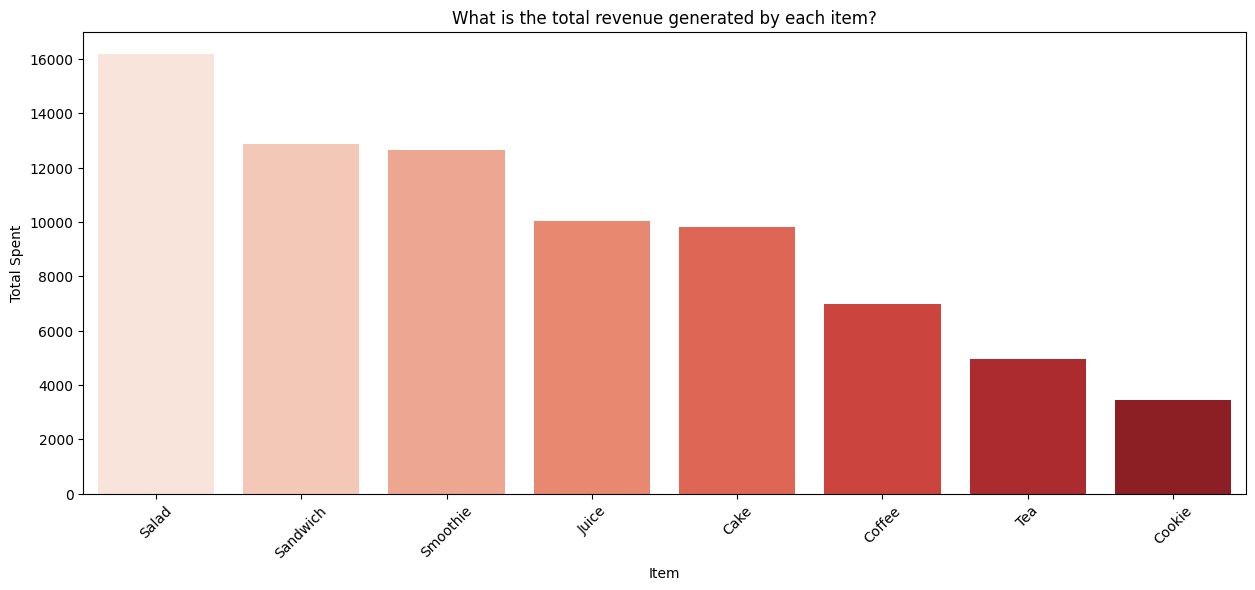

In [ ]:
plt.figure(figsize=(15, 6))
sns.barplot(x='Item', y='Total Spent', data=total_Revenue_each_item, palette='Reds' )
plt.title('What is the total revenue generated by each item?')
plt.xlabel('Item')
plt.ylabel('Total Spent')
plt.xticks(rotation=45)
plt.show()

# Which item has the highest total sales revenue?


In [ ]:
Highest_total_Sales_revenue = total_Revenue_each_item.loc[total_Revenue_each_item['Total Spent'].idxmax(), 'Item']
Highest_total_Sales_revenue

'Salad'

# what is the most ordered item 

In [ ]:
most_orderd_item = data.groupby('Item')[['Quantity']].sum().round().reset_index()
most_orderd_item

,Item,Quantity
0,Cake,3279.0
1,Coffee,3427.0
2,Cookie,3094.0
3,Juice,3352.0
4,Salad,3315.0
5,Sandwich,3268.0
6,Smoothie,3209.0
7,Tea,3126.0


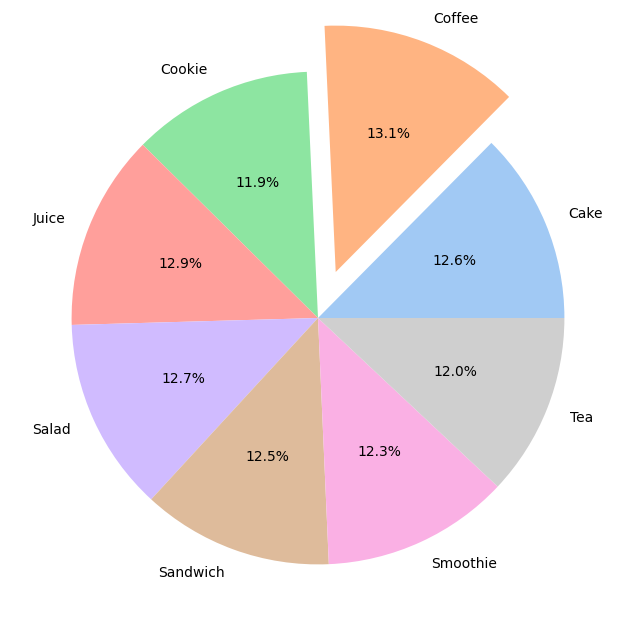

In [ ]:
plt.figure(figsize=(8, 8))
colors = sns.color_palette('pastel')

explode = [0.2 if x == most_orderd_item['Quantity'].max() else 0 for x in most_orderd_item['Quantity']]
plt.pie(most_orderd_item['Quantity'], labels=most_orderd_item['Item'], autopct='%1.1f%%', colors=colors, explode=explode)
plt.show()

# Time-based Analysis


# On which day of the week does the cafe see the highest sales volume?


In [ ]:
data["month_name"] = data['Transaction Date'].dt.month_name()
data["day_name"] = data['Transaction Date'].dt.day_name()


In [ ]:
sales_by_day = data.groupby(data['day_name'])['Total Spent'].sum().round(1).reset_index()
sales_by_day

,day_name,Total Spent
0,Friday,11263.7
1,Monday,10926.8
2,Saturday,10861.7
3,Sunday,11416.5
4,Thursday,11140.4
5,Tuesday,10926.7
6,Wednesday,10477.9


In [ ]:
highest_sales_day = sales_by_day.loc[sales_by_day['Total Spent'].idxmax()]
highest_sales_day

day_name        Sunday
Total Spent    11416.5
Name: 3, dtype: object

# What are the revenue trends across different months

In [ ]:
revenue_by_month = data.groupby(data['month_name'])['Total Spent'].sum().reset_index()
revenue_by_month = revenue_by_month.sort_values(by='Total Spent', ascending=False)
revenue_by_month

,month_name,Total Spent
10,October,6776.076144
4,January,6681.525215
6,June,6677.143714
7,March,6512.833508
9,November,6480.091388
0,April,6465.742330
2,December,6458.554340
1,August,6335.180375
8,May,6246.279120
11,September,6220.279335


# seasonal spikes

In [ ]:
seasonal_spikes_by_month = data.groupby(['month_name', 'Item'])['Total Spent'].sum().reset_index()
seasonal_spikes_by_month


,month_name,Item,Total Spent
0,April,Cake,810.182963
1,April,Coffee,532.777565
2,April,Cookie,225.913790
3,April,Juice,935.812119
4,April,Salad,1446.253712
...,...,...,...
91,September,Juice,747.062199
92,September,Salad,1131.192016
93,September,Sandwich,1112.196785
94,September,Smoothie,1162.263584


# Are there seasonal spikes in sales for specific items, like smoothies or cakes?


In [ ]:
seasonal_spikes = data[data['Item'].isin(['Coffee', 'Cake'])]
seasonal_spikes_by_month = seasonal_spikes.groupby(['month_name', 'Item'])['Total Spent'].sum().reset_index()

month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
seasonal_spikes_by_month['month_name'] = pd.Categorical(seasonal_spikes_by_month['month_name'], categories=month_order, ordered=True)
seasonal_spikes_by_month = seasonal_spikes_by_month.sort_values(by="month_name", ascending=True).reset_index(drop=True)

seasonal_spikes_by_month


,month_name,Item,Total Spent
0,January,Cake,866.789963
1,January,Coffee,577.370527
2,February,Cake,683.485200
3,February,Coffee,579.656800
4,March,Coffee,666.134270
5,March,Cake,810.312278
6,April,Cake,810.182963
7,April,Coffee,532.777565
8,May,Coffee,507.884507
9,May,Cake,830.255854


# DONE (: